# Kepler's equation and the analytical propagator

All functions come from the `orbits` package (`src/orbits`) and from the two scripts in `scripts/`; nothing is re-implemented here.
Units: km, s. Angles in radians inside the code, degrees only in output.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd().parent / "scripts"))  # reuse the scripts' functions

from compare_numerical import R0_A, V0_A, TOLERANCES, compute_all_errors, plot_position_errors
from newton_iterations import CASES, format_table, iteration_table
from orbits.constants import MU_EARTH, R_EARTH
from orbits.kepler import propagate_kepler
from orbits.twobody import orbital_quantities, propagate

## 1. Newton iterations: initial guess E0 = M vs E0 = pi

In [2]:
print(format_table(iteration_table(CASES)))

 M [rad]        e    E [rad]  it E0=M  it E0=pi
-----------------------------------------------
  1.0000  0.50000    1.49870        5         6
  3.6029  0.37255    3.47942        4         4
  0.1000  0.90000    0.63084        7         8
  6.0000  0.80000    5.36383        7         7
  0.0500  0.95000    0.53142        7         9
  0.0100  0.99000    0.34227        9        10


## 2. Position error: analytical propagator vs solve_ivp (RK45), orbit A over 3 periods

tight (rtol=1e-10, atol=1e-12)   max = 7.830e-05 km   final = 7.830e-05 km
loose (rtol=1e-3, atol=1e-6)     max = 9.911e+03 km   final = 9.557e+03 km
loose, after 3T: energy rel. error = +9.72%, delta a = -778.8 km, delta e = -0.0623


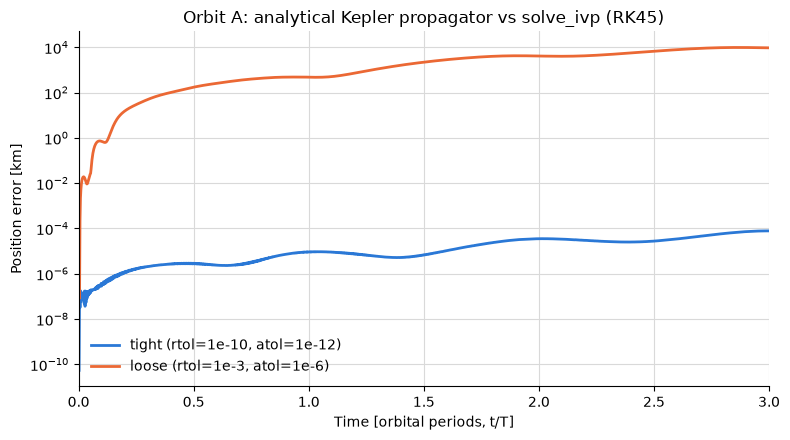

In [3]:
period, errors = compute_all_errors()
for label, (_, err) in errors.items():
    print(f"{label:32s} max = {err.max():.3e} km   final = {err[-1]:.3e} km")

# Drift of the orbital elements of the loose-tolerance solution after 3 periods.
loose = propagate(R0_A, V0_A, 3 * period, 2, **TOLERANCES["loose (rtol=1e-3, atol=1e-6)"])
q0 = orbital_quantities(R0_A, V0_A)
q_end = orbital_quantities(loose.y[:3, -1], loose.y[3:, -1])
print(f"loose, after 3T: energy rel. error = {q_end.energy / q0.energy - 1:+.2%}, "
      f"delta a = {q_end.a - q0.a:+.1f} km, delta e = {q_end.e_norm - q0.e_norm:+.4f}")

plot_position_errors(period, errors)
plt.show()

With tight tolerances RK45 keeps its local error near 1e-10, and the analytical solution has no step-size error at all, so the curve is the integrator's own accumulated error: about 1e-4 km (centimetres) after three orbits.
With loose tolerances every step leaks a little energy (printed above: a shrinks by hundreds of km), so the period shortens and the satellite drifts ahead of the true one by thousands of km; the orbit plane is still kept exactly and each revolution is a smooth, closed-looking ellipse, which is why a trajectory plot alone does not reveal the error.

## 3. Orbit B (e = 0.7) in the xy plane

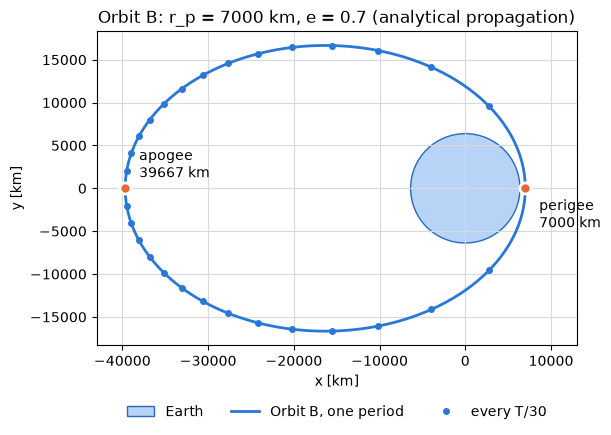

In [4]:
rp_b, e_b = 7000.0, 0.7
vp_b = np.sqrt(MU_EARTH * (1 + e_b) / rp_b)
r0_b, v0_b = np.array([rp_b, 0.0, 0.0]), np.array([0.0, vp_b, 0.0])
period_b = orbital_quantities(r0_b, v0_b).period

t = np.linspace(0.0, period_b, 721)
r_b = np.array([propagate_kepler(r0_b, v0_b, ti)[0] for ti in t])
r_apo, _ = propagate_kepler(r0_b, v0_b, period_b / 2)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.add_patch(plt.Circle((0, 0), R_EARTH, color="#b7d3f6", ec="#256abf", lw=1, label="Earth"))
ax.plot(r_b[:, 0], r_b[:, 1], color="#2a78d6", lw=2, label="Orbit B, one period")
ax.plot(r_b[::24, 0], r_b[::24, 1], "o", ms=4, color="#2a78d6", label="every T/30")
ax.plot(*r0_b[:2], "o", ms=8, color="#eb6834", mec="white", mew=2)
ax.plot(*r_apo[:2], "o", ms=8, color="#eb6834", mec="white", mew=2)
ax.annotate(f"perigee\n{np.linalg.norm(r0_b):.0f} km", r0_b[:2], xytext=(10, -28), textcoords="offset points")
ax.annotate(f"apogee\n{np.linalg.norm(r_apo):.0f} km", r_apo[:2], xytext=(10, 8), textcoords="offset points")
ax.set_aspect("equal")
ax.set_xlabel("x [km]")
ax.set_ylabel("y [km]")
ax.set_title("Orbit B: r_p = 7000 km, e = 0.7 (analytical propagation)")
ax.grid(True, color="0.85", linewidth=0.8)
ax.set_xlim(-43000, 13000)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
fig.tight_layout()
plt.show()

The markers are equally spaced in time (every T/30), so they crowd near apogee and thin out near perigee: the satellite sweeps equal areas in equal times (Kepler's second law) and moves fastest at perigee.
Perigee is only about 620 km above the Earth's surface while apogee is about 39700 km from the centre, so a single propagator has to handle radius and speed varying by a factor of about 5.7 along the same orbit.